# Cross-Lingual Embedding Test — Part 2: SEA-LION + LaBSE + Full Comparison

Tests two new models (SEA-LION, LaBSE), then loads the two from Part 1 (e5-small, BGE-M3) 
from local cache (no re-download) and compares all 4 together.


In [1]:
# Step 1: Load ALL 4 models from local cache (no download needed)

import os
# transformers would import TensorFlow (Keras 3) and fail; we only use PyTorch.
os.environ["USE_TF"] = "0"

from sentence_transformers import SentenceTransformer
import numpy as np

models = {}

print("Loading 4 models from cache (no internet needed)...")
print()

print("1/4  multilingual-e5-small...")
models["e5-small"] = {"model": SentenceTransformer("intfloat/multilingual-e5-small"),
                       "query_prefix": "query: ", "chunk_prefix": "passage: "}

print("2/4  BGE-M3...")
models["BGE-M3"] = {"model": SentenceTransformer("BAAI/bge-m3"),
                     "query_prefix": "", "chunk_prefix": ""}

print("3/4  SEA-LION-Embedding (built for Southeast Asian languages)...")
models["SEA-LION"] = {"model": SentenceTransformer("aisingapore/SEA-LION-ModernBERT-Embedding-300M"),
                       "query_prefix": "", "chunk_prefix": ""}

print("4/4  LaBSE (built for cross-lingual alignment)...")
models["LaBSE"] = {"model": SentenceTransformer("sentence-transformers/LaBSE"),
                    "query_prefix": "", "chunk_prefix": ""}

print()
print("All 4 models loaded.")


/mnt/mahdipou/miniconda3/envs/senv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading 4 models from cache (no internet needed)...

1/4  multilingual-e5-small...


2/4  BGE-M3...


3/4  SEA-LION-Embedding (built for Southeast Asian languages)...


4/4  LaBSE (built for cross-lingual alignment)...



All 4 models loaded.


In [2]:
# Step 2: Test data — 10 medical questions x 4 languages

questions = [
    {
        "topic": "Sepsis antibiotics",
        "en": "What antibiotics should be used for sepsis?",
        "km": "តើអង់ទីប៊ីយោទិចអ្វីខ្លះដែលគួរប្រើសម្រាប់ sepsis?",
        "lo": "ຄວນໃຊ້ຢາຕ້ານເຊື້ອຈຸລະຊີບອັນໃດສຳລັບ sepsis?",
        "vi": "Nên dùng kháng sinh nào cho sepsis?",
        "correct_chunk": "Sepsis and septic shock management. Empirical antibiotherapy selection based on suspected source. Broad spectrum antibiotics within one hour."
    },
    {
        "topic": "Hemorrhagic shock",
        "en": "How to manage hemorrhagic shock?",
        "km": "តើគ្រប់គ្រង hemorrhagic shock យ៉ាងដូចម្តេច?",
        "lo": "ຈັດການ hemorrhagic shock ແນວໃດ?",
        "vi": "Xử trí sốc mất máu như thế nào?",
        "correct_chunk": "Hemorrhagic shock management. Initial fluid resuscitation with crystalloids. Massive transfusion protocol activation. Control bleeding source."
    },
    {
        "topic": "NEWS-2 scoring",
        "en": "What are the NEWS-2 scoring parameters?",
        "km": "តើប៉ារ៉ាម៉ែត្រនៃការដាក់ពិន្ទុ NEWS-2 មានអ្វីខ្លះ?",
        "lo": "ຕົວກຳນົດການໃຫ້ຄະແນນ NEWS-2 ມີຫຍັງແດ່?",
        "vi": "Các thông số chấm điểm NEWS-2 là gì?",
        "correct_chunk": "National Early Warning Score NEWS-2. Parameters: respiratory rate, oxygen saturation SpO2, systolic blood pressure, pulse rate, consciousness, temperature."
    },
    {
        "topic": "Snake bite",
        "en": "How to treat snake bite?",
        "km": "តើព្យាបាលការខាំពស់យ៉ាងដូចម្តេច?",
        "lo": "ປິ່ນປົວງູກັດແນວໃດ?",
        "vi": "Điều trị rắn cắn như thế nào?",
        "correct_chunk": "Snake bite management. Identification of venomous species. Antivenom administration. Thai Red Cross antivenom dosing. Wound care and monitoring."
    },
    {
        "topic": "Anaphylaxis adrenaline",
        "en": "What is the dose of adrenaline in anaphylaxis?",
        "km": "តើកម្រិតថ្នាំ adrenaline ក្នុង anaphylaxis ប៉ុន្មាន?",
        "lo": "ປະລິມານຢາ adrenaline ໃນ anaphylaxis ແມ່ນຫຍັງ?",
        "vi": "Liều adrenaline trong phản vệ là bao nhiêu?",
        "correct_chunk": "Allergic reaction and anaphylaxis. Intramuscular epinephrine adrenaline 0.5mg adults. Second dose after 5 minutes if no improvement."
    },
    {
        "topic": "Paracetamol overdose",
        "en": "How to manage paracetamol overdose?",
        "km": "តើគ្រប់គ្រងការលើសកម្រិត paracetamol យ៉ាងដូចម្តេច?",
        "lo": "ຈັດການກິນ paracetamol ເກີນຂະໜາດແນວໃດ?",
        "vi": "Xử trí quá liều paracetamol như thế nào?",
        "correct_chunk": "Paracetamol acetaminophen poisoning. N-acetylcysteine NAC protocol. Rumack-Matthew nomogram. Treatment within 8 hours of ingestion."
    },
    {
        "topic": "Hyperkalemia",
        "en": "Emergency treatment of hyperkalemia",
        "km": "ការព្យាបាលបន្ទាន់នៃ hyperkalemia ដោយប្រើ calcium",
        "lo": "ການປິ່ນປົວສຸກເສີນ hyperkalemia ດ້ວຍ calcium",
        "vi": "Điều trị cấp cứu tăng kali máu bằng calcium",
        "correct_chunk": "Hyperkalemia emergency treatment. Calcium gluconate for cardiac membrane stabilization. Insulin and glucose for potassium shifting."
    },
    {
        "topic": "STEMI treatment",
        "en": "STEMI reperfusion therapy and timing",
        "km": "ការព្យាបាល reperfusion និងពេលវេលាសម្រាប់ STEMI",
        "lo": "ການປິ່ນປົວ reperfusion ແລະໄລຍະເວລາສຳລັບ STEMI",
        "vi": "Điều trị tái tưới máu STEMI và thời gian",
        "correct_chunk": "ST elevation myocardial infarction STEMI. Primary PCI within 90 minutes. Thrombolysis within 30 minutes. Dual antiplatelet therapy."
    },
    {
        "topic": "Heart failure",
        "en": "Heart failure treatment with ACE inhibitor",
        "km": "ការព្យាបាល heart failure ដោយប្រើ ACE inhibitor",
        "lo": "ການປិ່ນປົວ heart failure ດ້ວຍ ACE inhibitor",
        "vi": "Điều trị suy tim bằng thuốc ức chế ACE",
        "correct_chunk": "Chronic heart failure management. ACE inhibitors first line. Beta blockers. Mineralocorticoid receptor antagonists. SGLT2 inhibitors."
    },
    {
        "topic": "Hyponatremia",
        "en": "Correction of severe hyponatremia",
        "km": "ការកែតម្រូវ hyponatremia ធ្ងន់ធ្ងរដោយប្រើ sodium",
        "lo": "ການແກ້ໄຂ hyponatremia ຮ້າຍແຮງດ້ວຍ sodium",
        "vi": "Điều chỉnh hạ natri máu nặng bằng sodium",
        "correct_chunk": "Hyponatremia correction. Hypertonic saline 3 percent for severe cases. Maximum correction 8 mEq per liter per 24 hours."
    },
]

wrong_chunks = [
    "Diabetes mellitus type 2 management. Metformin as first line. HbA1c target below 7 percent.",
    "Pneumonia community acquired. Amoxicillin for mild cases. Chest X-ray for diagnosis.",
    "Asthma acute exacerbation. Salbutamol nebulizer. Oral prednisolone. Peak flow monitoring.",
]

all_chunks = [q["correct_chunk"] for q in questions] + wrong_chunks
print(f"Test data ready: {len(questions)} questions x 4 languages, searching among {len(all_chunks)} chunks")


Test data ready: 10 questions x 4 languages, searching among 13 chunks


In [3]:
# Step 3: Run ALL 4 models on the same test

all_results = []

for model_name, config in models.items():
    print(f"Testing {model_name}...")
    model = config["model"]
    qp = config["query_prefix"]
    cp = config["chunk_prefix"]
    
    # Embed all chunks once per model
    chunk_vectors = model.encode(
        [f"{cp}{c}" for c in all_chunks],
        normalize_embeddings=True
    )
    
    for q in questions:
        correct_position = questions.index(q)
        for lang in ["en", "km", "lo", "vi"]:
            query_vector = model.encode(
                [f"{qp}{q[lang]}"],
                normalize_embeddings=True
            )
            similarities = (query_vector @ chunk_vectors.T)[0]
            best_position = int(np.argmax(similarities))
            correct_sim = float(similarities[correct_position])
            
            all_results.append({
                "topic": q["topic"],
                "language": lang,
                "model": model_name,
                "similarity": round(correct_sim, 3),
                "found_correct": best_position == correct_position,
            })

print(f"\nDone! {len(all_results)} tests ({len(all_results)//4} per language)")


Testing e5-small...


Testing BGE-M3...


Testing SEA-LION...


/mnt/mahdipou/miniconda3/envs/senv/lib/python3.10/site-packages/torch/_inductor/compile_fx.py:194: UserWarning: TensorFloat32 tensor cores for float32 matrix multiplication available but not enabled. Consider setting `torch.set_float32_matmul_precision('high')` for better performance.
  warnings.warn(


Testing LaBSE...



Done! 160 tests (40 per language)


In [4]:
# Step 4: Results — all 4 models side by side

lang_names = {"en": "English", "km": "Khmer", "lo": "Lao", "vi": "Vietnamese"}
model_names = ["e5-small", "BGE-M3", "SEA-LION", "LaBSE"]

# Build summary
summary = {}
for model_name in model_names:
    summary[model_name] = {}
    model_results = [r for r in all_results if r["model"] == model_name]
    for lang in ["en", "km", "lo", "vi"]:
        lang_results = [r for r in model_results if r["language"] == lang]
        summary[model_name][lang] = {
            "sim": round(np.mean([r["similarity"] for r in lang_results]), 3),
            "acc": round(np.mean([r["found_correct"] for r in lang_results]), 2),
        }

# Print accuracy table
print("=" * 70)
print("TOP-1 ACCURACY — did the model find the correct chunk?")
print("=" * 70)
print(f"{'Model':<20} {'English':>10} {'Khmer':>10} {'Lao':>10} {'Vietnamese':>12}")
print("-" * 65)
for m in model_names:
    d = summary[m]
    print(f"{m:<20} {d['en']['acc']:>9.0%} {d['km']['acc']:>9.0%} {d['lo']['acc']:>9.0%} {d['vi']['acc']:>11.0%}")

# Print similarity table
print()
print("=" * 70)
print("SIMILARITY — how close was the query to the correct chunk? (0 to 1)")
print("=" * 70)
print(f"{'Model':<20} {'English':>10} {'Khmer':>10} {'Lao':>10} {'Vietnamese':>12} {'KH drop':>9}")
print("-" * 75)
for m in model_names:
    d = summary[m]
    drop = (d['en']['sim'] - d['km']['sim']) / d['en']['sim'] * 100
    print(f"{m:<20} {d['en']['sim']:>10.3f} {d['km']['sim']:>10.3f} {d['lo']['sim']:>10.3f} {d['vi']['sim']:>11.3f} {drop:>8.1f}%")


TOP-1 ACCURACY — did the model find the correct chunk?
Model                   English      Khmer        Lao   Vietnamese
-----------------------------------------------------------------
e5-small                  100%       90%       80%        100%
BGE-M3                    100%      100%      100%        100%
SEA-LION                  100%      100%      100%        100%
LaBSE                      90%      100%      100%         90%

SIMILARITY — how close was the query to the correct chunk? (0 to 1)
Model                   English      Khmer        Lao   Vietnamese   KH drop
---------------------------------------------------------------------------
e5-small                  0.898      0.856      0.844       0.828      4.7%
BGE-M3                    0.678      0.638      0.633       0.630      5.9%
SEA-LION                  0.863      0.780      0.782       0.784      9.6%
LaBSE                     0.470      0.476      0.460       0.439     -1.3%


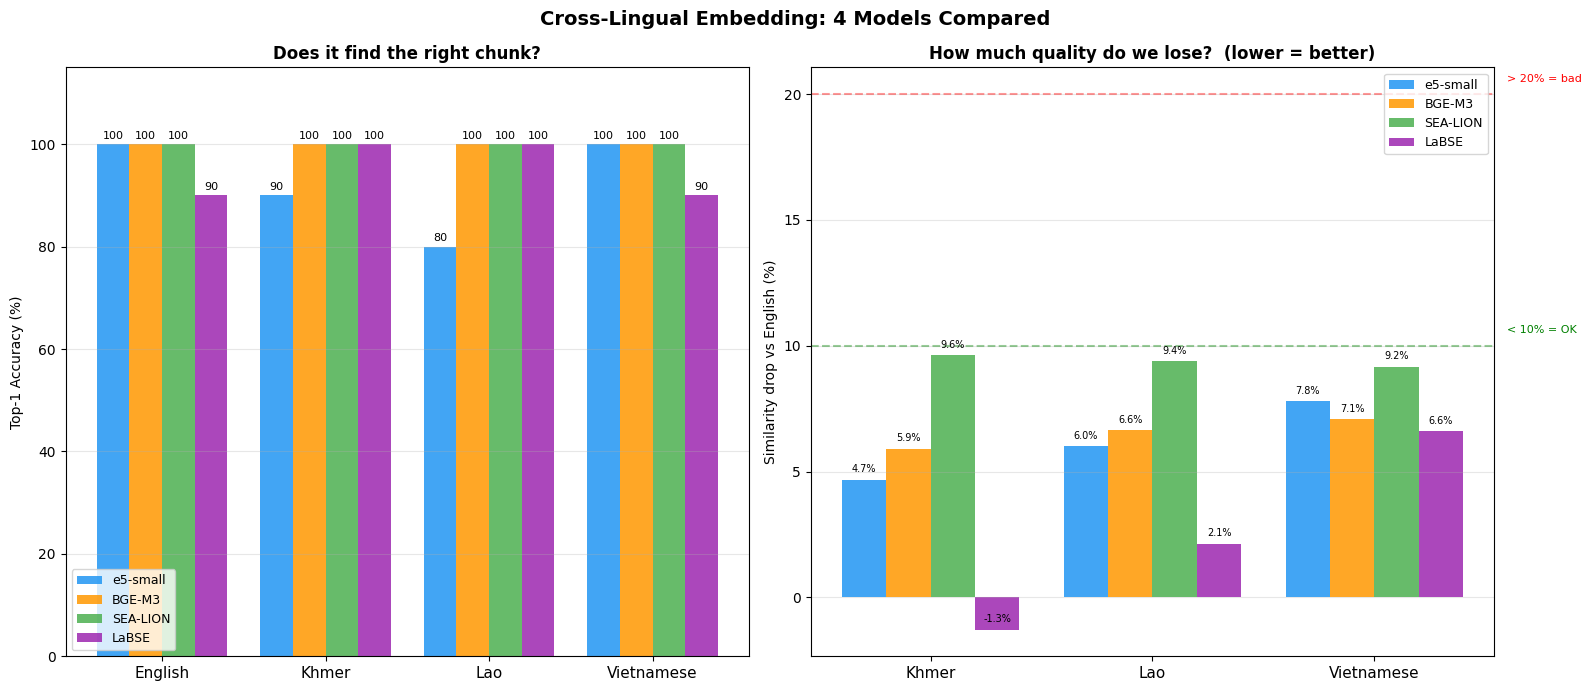

In [5]:
# Step 5: Visual comparison

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle("Cross-Lingual Embedding: 4 Models Compared",
             fontsize=14, fontweight="bold")

colors = {"e5-small": "#2196F3", "BGE-M3": "#FF9800", "SEA-LION": "#4CAF50", "LaBSE": "#9C27B0"}
langs = ["en", "km", "lo", "vi"]
lang_labels = ["English", "Khmer", "Lao", "Vietnamese"]

# Left: Top-1 accuracy
ax = axes[0]
x = np.arange(len(langs))
w = 0.2
for i, m in enumerate(model_names):
    vals = [summary[m][l]["acc"] * 100 for l in langs]
    bars = ax.bar(x + i*w - 1.5*w, vals, w, label=m, color=colors[m], alpha=0.85)
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1,
                f"{b.get_height():.0f}", ha="center", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(lang_labels, fontsize=11)
ax.set_ylabel("Top-1 Accuracy (%)")
ax.set_title("Does it find the right chunk?", fontweight="bold")
ax.legend(fontsize=9)
ax.set_ylim(0, 115)
ax.grid(axis="y", alpha=0.3)

# Right: Similarity drop from English
ax = axes[1]
for i, m in enumerate(model_names):
    en_sim = summary[m]["en"]["sim"]
    drops = [(en_sim - summary[m][l]["sim"]) / en_sim * 100 for l in ["km", "lo", "vi"]]
    x_pos = np.arange(3)
    bars = ax.bar(x_pos + i*w - 1.5*w, drops, w, label=m, color=colors[m], alpha=0.85)
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.3,
                f"{b.get_height():.1f}%", ha="center", fontsize=7)
ax.set_xticks(np.arange(3))
ax.set_xticklabels(["Khmer", "Lao", "Vietnamese"], fontsize=11)
ax.set_ylabel("Similarity drop vs English (%)")
ax.set_title("How much quality do we lose?  (lower = better)", fontweight="bold")
ax.legend(fontsize=9)
ax.axhline(y=10, color="green", linestyle="--", alpha=0.4)
ax.axhline(y=20, color="red", linestyle="--", alpha=0.4)
ax.text(2.6, 10.5, "< 10% = OK", fontsize=8, color="green")
ax.text(2.6, 20.5, "> 20% = bad", fontsize=8, color="red")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("out/all_models_comparison.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()


In [6]:
# Step 6: Final recommendation

print("=" * 70)
print("RECOMMENDATION")
print("=" * 70)

for lang, name in [("km", "Khmer"), ("lo", "Lao"), ("vi", "Vietnamese")]:
    best_model = max(model_names, key=lambda m: (summary[m][lang]["acc"], summary[m][lang]["sim"]))
    acc = summary[best_model][lang]["acc"]
    sim = summary[best_model][lang]["sim"]
    en_sim = summary[best_model]["en"]["sim"]
    drop = (en_sim - sim) / en_sim * 100
    
    needs_translate = "NO" if acc >= 0.8 and drop < 15 else "YES"
    
    print(f"\n  {name}:")
    print(f"    Best model: {best_model} (accuracy={acc:.0%}, drop={drop:.1f}%)")
    print(f"    Needs NLLB-200 translation? {needs_translate}")

print("\n" + "-" * 70)
avg_scores = {m: np.mean([summary[m][l]["acc"] for l in langs]) for m in model_names}
ranked = sorted(avg_scores, key=avg_scores.get, reverse=True)
print("\n  Overall ranking:")
for i, m in enumerate(ranked):
    print(f"    {i+1}. {m}: {avg_scores[m]:.0%} average accuracy")

print(f"\n  WINNER: {ranked[0]}")
print(f"\n  Caveat: queries still contain English medical terms.")
print(f"  A harder test with pure Khmer/Lao queries is recommended for Step 2.")


RECOMMENDATION

  Khmer:
    Best model: SEA-LION (accuracy=100%, drop=9.6%)
    Needs NLLB-200 translation? NO

  Lao:
    Best model: SEA-LION (accuracy=100%, drop=9.4%)
    Needs NLLB-200 translation? NO

  Vietnamese:
    Best model: e5-small (accuracy=100%, drop=7.8%)
    Needs NLLB-200 translation? NO

----------------------------------------------------------------------

  Overall ranking:
    1. BGE-M3: 100% average accuracy
    2. SEA-LION: 100% average accuracy
    3. LaBSE: 95% average accuracy
    4. e5-small: 92% average accuracy

  WINNER: BGE-M3

  Caveat: queries still contain English medical terms.
  A harder test with pure Khmer/Lao queries is recommended for Step 2.
